In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [3]:
import pandas as pd

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.info()

Dataset Shape: (1470, 35)

Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel   

In [6]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [7]:
df["Attrition"].value_counts()

,count
Attrition,
No,1233
Yes,237


In [8]:
df["Attrition"].value_counts(normalize=True) * 100

,proportion
Attrition,
No,83.877551
Yes,16.122449


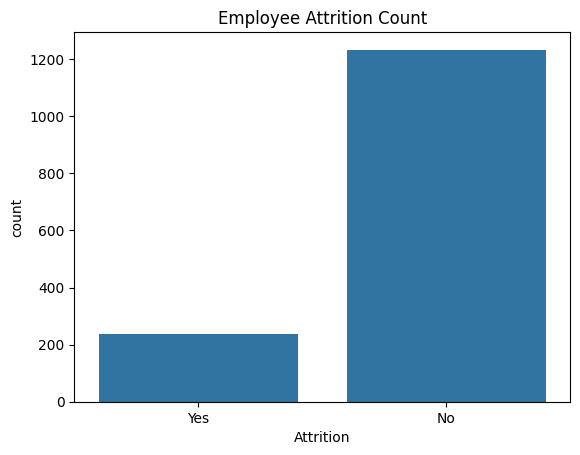

In [9]:
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Count")
plt.show()

In [10]:
pd.crosstab(df["Department"], df["Attrition"])

Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


In [11]:
attrition_rate = pd.crosstab(
    df["Department"],
    df["Attrition"],
    normalize="index"
) * 100

attrition_rate

Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


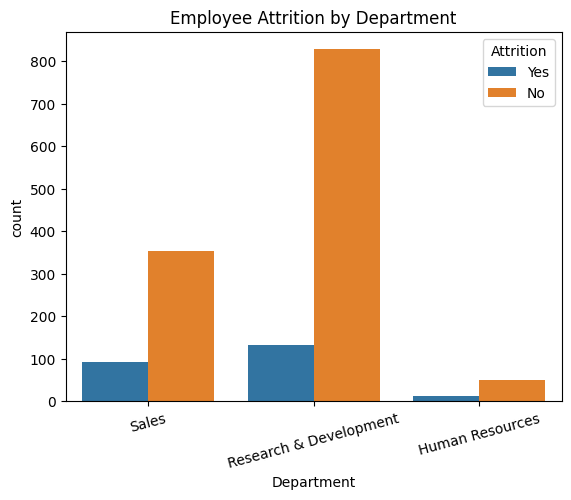

In [12]:
sns.countplot(data=df, x="Department", hue="Attrition")
plt.title("Employee Attrition by Department")
plt.xticks(rotation=15)
plt.show()

In [13]:
pd.crosstab(df["OverTime"], df["Attrition"])

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [14]:
overtime_rate = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

overtime_rate

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


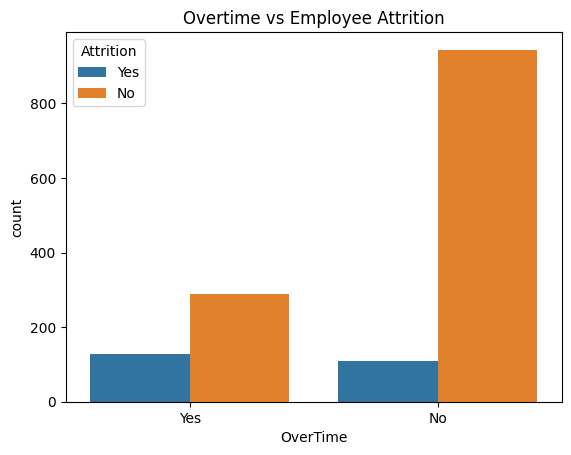

In [15]:
sns.countplot(data=df, x="OverTime", hue="Attrition")
plt.title("Overtime vs Employee Attrition")
plt.show()

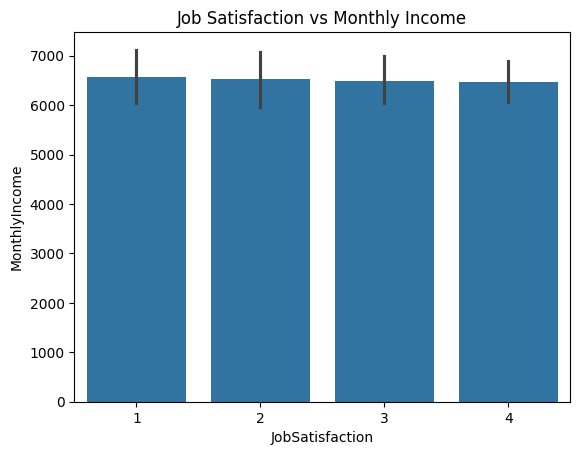

In [16]:
sns.barplot(data=df, x="JobSatisfaction", y="MonthlyIncome")
plt.title("Job Satisfaction vs Monthly Income")
plt.show()

In [17]:
df["SalaryGroup"] = pd.cut(
    df["MonthlyIncome"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

df[["MonthlyIncome", "SalaryGroup"]].head()

,MonthlyIncome,SalaryGroup
0,5993,Low
1,5130,Low
2,2090,Low
3,2909,Low
4,3468,Low


In [18]:
pd.crosstab(
    df["SalaryGroup"],
    df["Attrition"],
    normalize="index"
) * 100

Attrition,No,Yes
SalaryGroup,,
Low,81.679389,18.320611
Medium,85.767790,14.232210
High,95.483871,4.516129


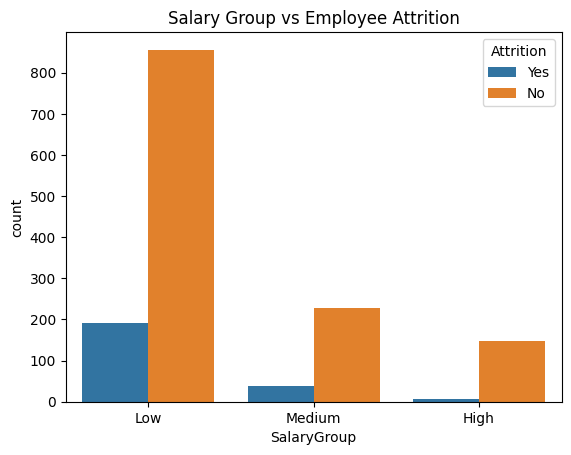

In [19]:
sns.countplot(data=df, x="SalaryGroup", hue="Attrition")
plt.title("Salary Group vs Employee Attrition")
plt.show()

In [20]:
pd.crosstab(df["JobRole"], df["Attrition"])

Attrition,No,Yes
JobRole,,
Healthcare Representative,122,9
Human Resources,40,12
Laboratory Technician,197,62
Manager,97,5
Manufacturing Director,135,10
Research Director,78,2
Research Scientist,245,47
Sales Executive,269,57
Sales Representative,50,33


In [21]:
role_attrition = pd.crosstab(
    df["JobRole"],
    df["Attrition"],
    normalize="index"
) * 100

role_attrition.sort_values("Yes", ascending=False)

Attrition,No,Yes
JobRole,,
Sales Representative,60.240964,39.759036
Laboratory Technician,76.061776,23.938224
Human Resources,76.923077,23.076923
Sales Executive,82.515337,17.484663
Research Scientist,83.904110,16.095890
Manufacturing Director,93.103448,6.896552
Healthcare Representative,93.129771,6.870229
Manager,95.098039,4.901961
Research Director,97.500000,2.500000


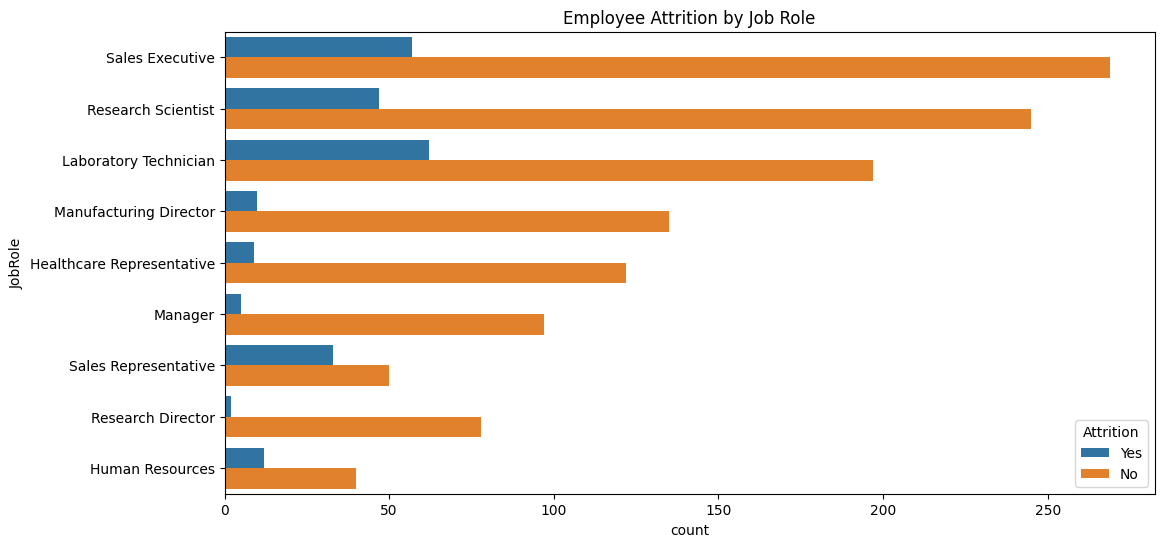

In [22]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="JobRole",
    hue="Attrition"
)

plt.title("Employee Attrition by Job Role")
plt.show()

In [23]:
total_employees = len(df)

employees_left = (df["Attrition"] == "Yes").sum()

attrition_rate = employees_left / total_employees * 100

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Attrition Rate:", round(attrition_rate, 2), "%")

Total Employees: 1470
Employees Left: 237
Attrition Rate: 16.12 %


In [24]:
department_rate = pd.crosstab(
    df["Department"],
    df["Attrition"],
    normalize="index"
) * 100

print(department_rate.sort_values("Yes", ascending=False))

Attrition                      No        Yes
Department                                  
Sales                   79.372197  20.627803
Human Resources         80.952381  19.047619
Research & Development  86.160250  13.839750
